# Variational Assimilation: Strong-Constraint 4D-Var with vardax

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jejjohnson/sesmax/blob/main/docs/notebooks/data_assimilation_4dvar.ipynb)

*Part of the data-assimilation series; moved from somax's tutorial series.*

The [ensemble page](data_assimilation_etkf.ipynb) corrected a state with filterax, window by window. This page takes the variational route: [vardax](https://github.com/jejjohnson/vardax)'s strong-constraint 4D-Var finds the one initial state whose model trajectory best fits a whole window of observations, held near a background.

**What you'll learn:**

1. How `VardaxForwardModel` exposes a sesmax model as a vardax forward model
2. How to build a structured background covariance with [gaussx](https://github.com/jejjohnson/gaussx)
3. How the analysis pulls a poor background toward the truth
4. How reliable this is on a chaotic model, and how the incremental form compares
5. How to estimate a forcing that changes in time, with `WindowOperator`

:::{note}
This page needs the optional `[da]` extra, which provides vardax and gaussx: `pip install sesmax-core[da]`.
:::

## Setup

On Colab, install `sesmax-core` with its `[da]` extra; locally, with the repository's environment, this does nothing.

In [1]:
import subprocess
import sys


try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "sesmax-core[da] @ git+https://github.com/jejjohnson/sesmax@main"
            "#subdirectory=packages/sesmax-core",
        ],
        check=True,
    )

## The cost

The observations follow {eq}`da-observation`, here with every variable observed. Strong-constraint 4D-Var treats the model as exact, so the whole trajectory follows from the initial state, and it minimises a cost over that state alone:

$$\mathcal{J}(\mathbf{x}_0) = \frac{1}{2} \Vert \mathbf{x}_0 - \boldsymbol{\mu}_x \Vert^2_{\boldsymbol{\Sigma}_x^{-1}} + \frac{1}{2} \sum_{t=0}^{N_T} \Vert \mathbf{y}_t - \mathbf{H} f_t(\mathbf{x}_0; F) \Vert^2_{\boldsymbol{\Sigma}_\varepsilon^{-1}}$$ (da-4dvar-cost)

The first term holds the analysis near the background, and the second fits the observations through the model, so its gradient runs back through every step of the window.

### Symbols

| Symbol | Meaning | Shape |
| --- | --- | --- |
| $\mathbf{x}_0$ | initial state, the control | $\mathbb{R}^{D_x}$ |
| $\mathbf{x}_0^\star$ | the analysis, the minimiser of $\mathcal{J}$ | $\mathbb{R}^{D_x}$ |
| $\boldsymbol{\mu}_x$, $\boldsymbol{\Sigma}_x$ | background mean and covariance | $\mathbb{R}^{D_x}$, $D_x \times D_x$ |
| $\mathbf{y}_t$ | observations at step $t$ | $\mathbb{R}^{D_y}$ |
| $\mathbf{H}$ | observation operator, here the identity | $D_y \times D_x$ |
| $\boldsymbol{\Sigma}_\varepsilon$ | observation-error covariance | $D_y \times D_y$ |
| $f_t(\mathbf{x}_0; F)$, $F$ | the model run for $t$ steps from $\mathbf{x}_0$, and its forcing | $\mathbb{R}^{D_x}$, $\mathbb{R}$ |
| $N_T$ | number of steps in the window | count |
| $\mathcal{J}$ | cost over the state, minimised | $\mathbb{R}$ |

### The bridge

vardax's solvers consume a `ForwardModel`, an object with `dt` and `step(state, dt)`, and roll it out over the window on a flat state vector. `VardaxForwardModel` wraps a sesmax model to that contract, as `FilteraxDynamics` did for the ensemble filter. The model is shared; only the analysis differs. The adapter passes the same `t0` on every substep, so it is exact only for autonomous models, like this one ([#73](https://github.com/jejjohnson/sesmax/issues/73)).

In [2]:
import diffrax as dfx
import equinox as eqx
import gaussx
import jax
import jax.numpy as jnp
import lineax as lx
import matplotlib.pyplot as plt
import numpy as np
import optax
from vardax import (
    Batch1D,
    IncrementalFourDVar,
    MaskedIdentity,
    OptaxMinimiser,
    StrongFourDVar,
    ThreeDVar,
)

import sesmax_core.testing as sxt
from sesmax_core import BasisForcing, HatInTime, SpatialBasis
from sesmax_core.da import VardaxForwardModel, WindowOperator, state_to_vector

In [3]:
import importlib.util


try:
    from IPython import get_ipython

    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None and importlib.util.find_spec("watermark") is not None:
    ipython.run_line_magic("load_ext", "watermark")
    ipython.run_line_magic("watermark", "-v -m -p jax,equinox,diffrax,sesmax_core")
else:
    print("watermark extension not installed; skipping reproducibility readout.")

Python implementation: CPython
Python version       : 3.13.12
IPython version      : 9.10.0

jax        : 0.12.0.1
equinox    : 0.13.8
diffrax    : 0.7.2
sesmax_core: 0.0.0

Compiler    : Clang 21.1.4 
OS          : Linux
Release     : 6.8.0-1044-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 16
Architecture: 64bit



## 1. Truth, model and adapter

We use a 12-variable Lorenz '96 system at $F = 8$, spun onto its attractor. The `template` state fixes the layout between the flat vector and the pytree.

In [4]:
# Shapes: D_x = 12 variables; N_T = 3 window steps

num_variables = 12
time_step = 0.05
window_steps = 3
obs_variance = 0.04

# today (sesmax_core)
model = sxt.Lorenz96.create(F=8.0)
# today (jax, sesmax_core)
step = jax.jit(lambda state: model.step(state, time_step))

# x₀ = F, with a small perturbation on the first variable
near_equilibrium = 8.0 * jnp.ones(num_variables)  # → (D_x,)
# today (sesmax_core)
truth_state = sxt.L96State(x=near_equilibrium.at[0].add(0.01))
for _ in range(200):
    truth_state = step(truth_state)
# today (sesmax_core)
initial_truth, _ = state_to_vector(truth_state)  # → (D_x,)
forward = VardaxForwardModel(model=model, template=truth_state, dt=time_step)
print(f"Forward model dt: {forward.dt}")

Forward model dt: 0.05


## 2. The observation window

Strong 4D-Var fits a trajectory, so we roll the truth forward and observe every variable at every time with Gaussian noise. vardax packs the window into a `Batch1D` with a validity mask.

In [5]:
# Shapes: D_x = 12 variables; N_T + 1 = 4 observation times

trajectory = [initial_truth]
state = truth_state
for _ in range(window_steps):
    state = step(state)
    # today (sesmax_core)
    vector, _ = state_to_vector(state)  # → (D_x,)
    trajectory.append(vector)
trajectory = jnp.stack(trajectory)  # → (N_T + 1, D_x)

# ε_t ~ 𝒩(0, Σ_ε)
noise = jnp.sqrt(obs_variance) * jax.random.normal(  # → (N_T + 1, D_x)
    jax.random.key(0), trajectory.shape
)
# today (vardax)
# y_t = H x_t + ε_t, with a leading batch axis
batch = Batch1D(
    input=(trajectory + noise)[None],
    mask=jnp.ones_like(trajectory)[None],
    target=trajectory[None],
)
print(f"Observation window: {batch.input.shape}")

Observation window: (1, 4, 12)


## 3. A structured background covariance

The background term in {eq}`da-4dvar-cost` needs $\boldsymbol{\Sigma}_x$. Rather than a plain diagonal, we build a diagonal plus low-rank covariance with `gaussx.LowRankUpdate`, then materialise it as a dense operator because vardax's solver needs one. The low-rank term adds spatial correlations.

In [6]:
# Shapes: D_x = 12 variables; 2 low-rank directions

psd = lx.positive_semidefinite_tag
# U, the low-rank directions
low_rank_key = jax.random.key(2)
directions = 0.3 * jax.random.normal(low_rank_key, (num_variables, 2))  # → (D_x, 2)
# today (lineax)
diagonal = lx.DiagonalLinearOperator(0.5 * jnp.ones(num_variables))
# today (gaussx)
# Σ_x = 0.5 I + U Uᵀ
structured = gaussx.LowRankUpdate(diagonal, directions, jnp.ones(2), tags=psd)
background_covariance = lx.MatrixLinearOperator(structured.as_matrix(), psd)
# today (lineax)
# Σ_ε = σ² I
obs_covariance = lx.MatrixLinearOperator(obs_variance * jnp.eye(num_variables), psd)

condition = jnp.linalg.cond(structured.as_matrix())  # → ()
print(f"Condition number of the background covariance: {float(condition):.2f}")

Condition number of the background covariance: 3.69


## 4. Run strong-constraint 4D-Var

The background is the truth corrupted by a perturbation, which is what 4D-Var has to correct. `StrongFourDVar` minimises {eq}`da-4dvar-cost`, with gradients flowing through the rollout by automatic differentiation.

In [7]:
# Shapes: D_x = 12 variables

# μ_x = x₀ + 0.3 z, z ~ 𝒩(0, I)
perturbation = jax.random.normal(jax.random.key(1), (num_variables,))  # → (D_x,)
background = initial_truth + 0.3 * perturbation  # → (D_x,)

# today (vardax)
strong = StrongFourDVar(
    forward=forward,
    obs_op=MaskedIdentity(),
    prior_mean=background,
    prior_cov_op=background_covariance,
    obs_cov_op=obs_covariance,
)
# x₀* = argmin 𝒥(x₀)
analysis = strong(batch)[0]  # → (D_x,)

# ‖μ_x − x₀‖_RMS
background_rmse = jnp.sqrt(jnp.mean((background - initial_truth) ** 2))  # → ()
# ‖x₀* − x₀‖_RMS
analysis_rmse = jnp.sqrt(jnp.mean((analysis - initial_truth) ** 2))  # → ()
reduction = 100.0 * (1.0 - analysis_rmse / background_rmse)  # → ()
print(f"Background RMSE: {float(background_rmse):.4f}")
print(f"Analysis RMSE:   {float(analysis_rmse):.4f}")
print(f"Error reduction: {float(reduction):.0f}%")

Background RMSE: 0.2460
Analysis RMSE:   0.0894
Error reduction: 64%


## 5. Does it work?

The analysis sits closer to the truth than the background it started from: the observation window has pulled $\mathbf{x}_0$ back toward the truth.

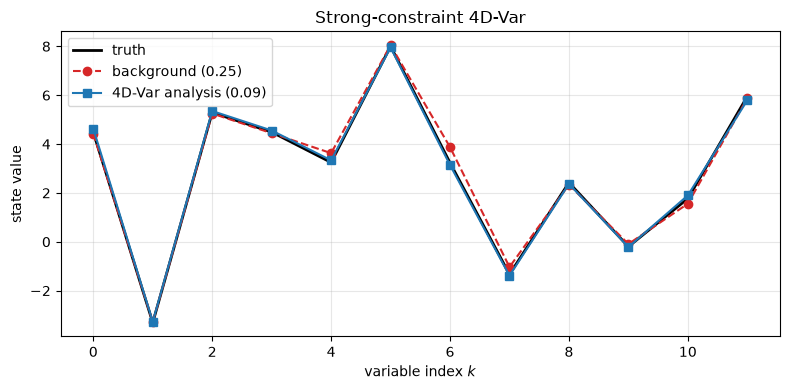

In [8]:
positions = jnp.arange(num_variables)  # → (D_x,)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(positions, initial_truth, "k-", lw=2, label="truth")
background_label = f"background ({float(background_rmse):.2f})"
ax.plot(positions, background, "o--", color="C3", label=background_label)
analysis_label = f"4D-Var analysis ({float(analysis_rmse):.2f})"
ax.plot(positions, analysis, "s-", color="C0", label=analysis_label)
ax.set_xlabel("variable index $k$")
ax.set_ylabel("state value")
ax.set_title("Strong-constraint 4D-Var")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 6. How reliable is this?

The run above is one window from one point on the attractor, and a chaotic model does not always cooperate: a trial step of the minimiser can push the rollout to non-finite values, and `StrongFourDVar` then stops with an error. So we repeat the experiment from six points further along the trajectory.

`IncrementalFourDVar` minimises the same cost {eq}`da-4dvar-cost` by Gauss–Newton outer iterations, linearising the model around the current estimate, with conjugate-gradient inner iterations. It differentiates the model in forward mode, which diffrax's default adjoint does not support, so its adapter takes `adjoint=diffrax.DirectAdjoint()`.

In [9]:
# Shapes: D_x = 12 variables; N_T + 1 = 4 observation times; 6 truths


def twin_experiment(start_state, seed, make_solver):
    """One twin run; returns the analysis RMSE, or None if the solver failed."""
    # today (sesmax_core)
    start_vector, _ = state_to_vector(start_state)  # → (D_x,)
    vectors = [start_vector]
    current = start_state
    for _ in range(window_steps):
        current = step(current)
        # today (sesmax_core)
        vectors.append(state_to_vector(current)[0])
    window_truth = jnp.stack(vectors)  # → (N_T + 1, D_x)
    # ε_t ~ 𝒩(0, Σ_ε)
    window_noise = jnp.sqrt(obs_variance) * jax.random.normal(
        jax.random.key(seed), window_truth.shape
    )
    # today (vardax)
    window = Batch1D(
        input=(window_truth + window_noise)[None],
        mask=jnp.ones_like(window_truth)[None],
        target=None,
    )
    # μ_x = x₀ + 0.3 z, z ~ 𝒩(0, I)
    start_noise = jax.random.normal(jax.random.key(100 + seed), (num_variables,))
    prior_mean = start_vector + 0.3 * start_noise  # → (D_x,)
    solver = make_solver(start_state, prior_mean)
    try:
        estimate = solver(window)[0]  # → (D_x,)
    except eqx.EquinoxRuntimeError:
        return None
    # ‖x₀* − x₀‖_RMS
    return float(jnp.sqrt(jnp.mean((estimate - start_vector) ** 2)))


def make_strong(template, prior_mean):
    # today (sesmax_core, vardax)
    return StrongFourDVar(
        forward=VardaxForwardModel(model=model, template=template, dt=time_step),
        obs_op=MaskedIdentity(),
        prior_mean=prior_mean,
        prior_cov_op=background_covariance,
        obs_cov_op=obs_covariance,
    )


def make_incremental(template, prior_mean):
    # today (sesmax_core, diffrax, vardax)
    return IncrementalFourDVar(
        forward=VardaxForwardModel(
            model=model, template=template, dt=time_step, adjoint=dfx.DirectAdjoint()
        ),
        obs_op=MaskedIdentity(),
        prior_mean=prior_mean,
        prior_cov_op=background_covariance,
        obs_cov_op=obs_covariance,
    )


def report(result):
    return "failed" if result is None else f"{result:.3f}"


print("truth   strong   incremental")
start_state = truth_state
for seed in range(6):
    strong_result = twin_experiment(start_state, seed, make_strong)
    incremental_result = twin_experiment(start_state, seed, make_incremental)
    print(f"{seed:5d}   {report(strong_result):6s}   {report(incremental_result)}")
    # Forty steps along the trajectory, for the next truth
    for _ in range(40):
        start_state = step(start_state)

truth   strong   incremental


    0   0.092    0.092


    1   failed   0.157


    2   failed   0.118


    3   0.091    0.091


    4   0.101    0.101


    5   failed   0.140


The table prints the analysis RMSE for each truth, against a background error near 0.3. Where both solvers finish they land on about the same answer, as they should, since they minimise the same cost. The difference is whether they finish, and longer windows are harder still for both. Strong-constraint 4D-Var over a chaotic model is sensitive to the window, the background and the point on the attractor, so test a configuration before relying on it.

## 7. A forcing that changes in time

Everything above estimates an initial state for an autonomous model. `VardaxForwardModel` passes the same start time on every substep, so it cannot carry a forcing that depends on time. To estimate one, treat the whole window as a single map from the control to the stacked observations, so that the model integrates with its own clock:

$$\mathcal{G}(\boldsymbol{\theta}) = \mathrm{vec}\left[\mathbf{H} \mathbf{x}(t_k; \boldsymbol{\theta})\right]_{k=1}^{N_T}$$ (da-window-map)

The control is now $\boldsymbol{\theta}$ rather than $\mathbf{x}_0$. The cost has the form of {eq}`da-4dvar-cost` with the model inside the observation operator, which is a 3D-Var cost over the control:

$$\mathcal{J}(\boldsymbol{\theta}) = \frac{1}{2} \Vert \boldsymbol{\theta} - \boldsymbol{\mu}_\theta \Vert^2_{\boldsymbol{\Sigma}_\theta^{-1}} + \frac{1}{2} \Vert \mathbf{y} - \mathcal{G}(\boldsymbol{\theta}) \Vert^2_{\boldsymbol{\Sigma}_\varepsilon^{-1}}$$ (da-window-cost)

| Symbol | Meaning | Shape |
| --- | --- | --- |
| $\boldsymbol{\theta}$ | the forcing's value at each knot, the control | $\mathbb{R}^{D_\theta}$ |
| $\boldsymbol{\mu}_\theta$, $\boldsymbol{\Sigma}_\theta$ | prior mean and covariance of the control | $\mathbb{R}^{D_\theta}$, $D_\theta \times D_\theta$ |
| $\mathbf{x}(t_k; \boldsymbol{\theta})$ | the model state at observation time $t_k$ | $\mathbb{R}^{D_x}$ |
| $\mathbf{y}$ | the observations, stacked over time | $\mathbb{R}^{N_T D_y}$ |

Here $\boldsymbol{\Sigma}_\varepsilon$ is the observation-error covariance of the stacked vector.

We add to Lorenz '96 a uniform forcing whose value is set at five knots and interpolated linearly between them, which is what `HatInTime` gives a `BasisForcing`. The truth is one such series, and half of the variables are observed eight times through the window.

In [10]:
# Shapes: D_x = 12 variables; D_θ = 5 knots; N_T = 8 times; D_y = 6 per time


class ForcedLorenz96(sxt.Lorenz96):
    """Lorenz '96 with a time-varying addition to its constant forcing."""

    forcing: BasisForcing = eqx.field(kw_only=True)

    def vector_field(self, t, state, args=None):
        free = super().vector_field(t, state, args)
        # dxᵢ/dt = free + Σₖ θₖ bₖ(t)
        return sxt.L96State(x=free.x + self.forcing(t))


num_knots = 5
true_series = jnp.array([0.0, 2.0, -1.0, 1.5, 0.5])  # → (D_θ,)
prior_series = jnp.zeros(num_knots)  # → (D_θ,)
series_noise_std = 0.05
# today (sesmax_core)
uniform = SpatialBasis.from_array(
    jnp.ones((num_variables, num_knots)), std=jnp.ones(num_knots)
)


def make_window(start_state, window_length):
    """The map 𝒢 from a series to the stacked observations of one window."""
    # today (sesmax_core)
    in_time = HatInTime(knots=jnp.linspace(0.0, window_length, num_knots))

    def model_for_series(series):
        # today (sesmax_core)
        # f(t) = Σₖ θₖ bₖ(t), on every variable
        forcing = BasisForcing(
            coeffs=series,  # (D_θ,)
            spatial=uniform,
            temporal=in_time,
            grid_shape=(num_variables,),
        )
        return ForcedLorenz96(
            params=model.params, advection=model.advection, forcing=forcing
        )

    # today (sesmax_core)
    # 𝒢(θ) = vec[H x(tₖ; θ)]
    return WindowOperator(  # (D_θ,) → (N_T D_y,)
        build_model=model_for_series,
        initial_state=start_state,
        obs_op=lambda state: state.x[::2],
        save_times=jnp.linspace(window_length / 8, window_length, 8),
        dt=time_step,
    )


def observe(window_operator, seed):
    # y = 𝒢(θ_true) + ε, ε ~ 𝒩(0, Σ_ε)
    clean_stack = window_operator(true_series)  # → (N_T D_y,)
    noise = jax.random.normal(jax.random.key(seed), clean_stack.shape)
    return clean_stack + series_noise_std * noise


def window_cost(window_operator, observed_stack, series):
    # ½ ‖θ‖² + ½ ‖y − 𝒢(θ)‖²_Σ_ε⁻¹, with μ_θ = 0 and Σ_θ = I
    misfit = (observed_stack - window_operator(series)) / series_noise_std
    return 0.5 * jnp.sum(series**2) + 0.5 * jnp.sum(misfit**2)


window_operator = make_window(truth_state, 0.5)
observed_stack = observe(window_operator, 0)  # → (N_T D_y,)

A gradient at the prior shows why the minimiser matters. With observations this precise, a quasi-Newton solver's first step is along a large gradient, so we check whether the model survives it.

In [11]:
# Shapes: D_θ = 5 knots

prior_gradient = jax.grad(
    lambda series: window_cost(window_operator, observed_stack, series)
)(prior_series)  # → (D_θ,)
# θ₁ = μ_θ − ∇𝒥(μ_θ)
first_step = window_operator(prior_series - prior_gradient)  # → (N_T D_y,)
print(f"Gradient norm at the prior: {float(jnp.linalg.norm(prior_gradient)):.0f}")
print(f"Model finite after a unit step: {bool(jnp.all(jnp.isfinite(first_step)))}")

Gradient norm at the prior: 1104
Model finite after a unit step: False


So we minimise with Adam, whose step does not grow with the gradient. `as_obs_op` gives the operator that `ThreeDVar` needs, with vardax's leading row. The figure shows a window of half a time unit from the same start as the rest of this page.

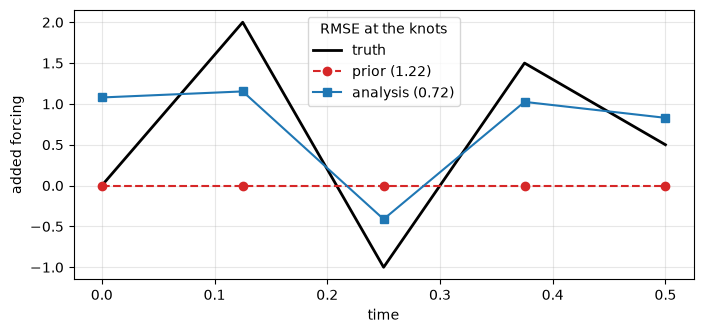

In [12]:
# Shapes: D_θ = 5 knots; N_T D_y = 48 stacked observations

psd = frozenset({lx.symmetric_tag, lx.positive_semidefinite_tag})


def estimate_series(window_operator, observed_stack):
    stack_size = observed_stack.size
    # today (vardax, sesmax_core, optax)
    # θ* = argmin 𝒥(θ)
    solver = ThreeDVar(
        obs_op=window_operator.as_obs_op(),
        prior_mean=jnp.zeros((1, num_knots)),
        prior_cov_op=lx.IdentityLinearOperator(
            jax.ShapeDtypeStruct((1, num_knots), observed_stack.dtype)
        ),
        obs_cov_op=lx.FunctionLinearOperator(
            lambda vector: series_noise_std**2 * vector,
            jax.ShapeDtypeStruct((1, stack_size), observed_stack.dtype),
            psd,
        ),
        minimiser=OptaxMinimiser(optax.adam(0.05), max_steps=300),
        cov_solver=lx.AutoLinearSolver(well_posed=True),
    )
    # today (vardax)
    batch = Batch1D(input=observed_stack[None, None], mask=jnp.ones((1, 1, stack_size)))
    return solver(batch)[0, 0]  # → (D_θ,)


def series_rmse(series):
    # ‖θ − θ_true‖_RMS
    return float(jnp.sqrt(jnp.mean((series - true_series) ** 2)))


series_estimate = estimate_series(window_operator, observed_stack)  # → (D_θ,)

knots = np.linspace(0.0, 0.5, num_knots)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(knots, true_series, "k-", lw=2, label="truth")
prior_label = f"prior ({series_rmse(prior_series):.2f})"
ax.plot(knots, prior_series, "o--", color="C3", label=prior_label)
estimate_label = f"analysis ({series_rmse(series_estimate):.2f})"
ax.plot(knots, series_estimate, "s-", color="C0", label=estimate_label)
ax.set_xlabel("time")
ax.set_ylabel("added forcing")
ax.legend(title="RMSE at the knots")
ax.grid(alpha=0.3)
plt.show()

One window from one start says little on a chaotic model, so the table runs three window lengths from three starts on the attractor. Alongside the error, it prints the cost at the analysis and at the truth. If the analysis costs about what the truth does, the solve has done its job, and if it costs far more, the minimiser stopped short of a better point that exists.

In [13]:
# Shapes: 3 window lengths; 3 starts

print("window  start  prior   analysis   J(analysis)   J(truth)")
for window_length in (0.5, 1.0, 2.0):
    start_state = truth_state
    for seed in range(3):
        operator = make_window(start_state, window_length)
        stack = observe(operator, seed)
        estimate = estimate_series(operator, stack)
        estimate_cost = float(window_cost(operator, stack, estimate))
        truth_cost = float(window_cost(operator, stack, true_series))
        print(
            f"{window_length:6.1f}  {seed:5d}  {series_rmse(prior_series):5.2f}"
            f"  {series_rmse(estimate):8.2f}  {estimate_cost:12.1f}  {truth_cost:9.1f}"
        )
        # Forty steps along the trajectory, for the next start
        for _ in range(40):
            start_state = step(start_state)

window  start  prior   analysis   J(analysis)   J(truth)


   0.5      0   1.22      0.72          27.9       27.8


   0.5      1   1.22      0.65          25.0       31.1


   0.5      2   1.22      0.28          32.1       31.8


   1.0      0   1.22      0.88          63.0       27.8


   1.0      1   1.22      0.33          39.1       31.1


   1.0      2   1.22      0.42          44.3       31.8


   2.0      0   1.22      2.48       26196.3       27.8


   2.0      1   1.22      0.13          33.0       31.1


   2.0      2   1.22      0.05          33.9       31.8


In the figure, the analysis follows the changes of sign but underestimates the peaks, and it is furthest off at the first knot. Its cost matches the truth's, so that error is not a failed solve.

In the table, the analysis beats the prior in eight of the nine runs. At half a time unit, every solve reaches about the truth's cost. At one time unit, the costs stay above the truth's, though the errors are still below the prior's. At two time units, two runs give the smallest errors in the table, and the third stops at a cost about a thousand times the truth's, with an error worse than the prior's. So a longer window can constrain the series better and can also defeat the minimiser, and we have not established why this start fails. Comparing the two costs, as here, is how to tell which has happened.

None of this changes the model or puts time in the state, since `model.integrate` carries the clock. It inverts for a forcing or a parameter and not for an initial state, so it complements `VardaxForwardModel` rather than replacing it.

## Summary

| Concept | sesmax and stack API |
| --- | --- |
| Forward model for a variational solver | `VardaxForwardModel(model=model, template=state, dt=dt)` |
| Flatten a state | `state_to_vector(state)` |
| Observation window | `vardax.Batch1D(input=..., mask=..., target=...)` |
| Structured covariance | `gaussx.LowRankUpdate(...)` |
| The analysis | `vardax.StrongFourDVar(...)(batch)[0]` |
| Incremental form | `VardaxForwardModel(..., adjoint=diffrax.DirectAdjoint())` with `vardax.IncrementalFourDVar` |
| A time-varying forcing | `HatInTime(knots)` in a `BasisForcing`, and `WindowOperator(...).as_obs_op()` with `vardax.ThreeDVar` |